In [1]:
%load_ext autoreload
%autoreload 2

# Device selection

In [2]:
from cobos.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService

channel = "ibm_quantum"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
device = "ibm_marrakesh"
# device = "ibm_aachen"
# device = "ibm_kingston"

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

/var/folders/t9/xqv32vzn2pb091tj9_rz1_zh0000gn/T/ipykernel_12034/664675149.py:12: DeprecationWarning: The "ibm_quantum" channel option is deprecated and will be sunset on 1 July. After this date, ibm_cloud will be the only valid channel. For information on migrating to the new IBM Quantum Platform on the "ibm_cloud" channel, review the migration guide https://quantum.cloud.ibm.com/docs/migration-guides/classic-iqp-to-cloud-iqp .
  service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)


# Auxiliary lattice plot

18 possible layouts


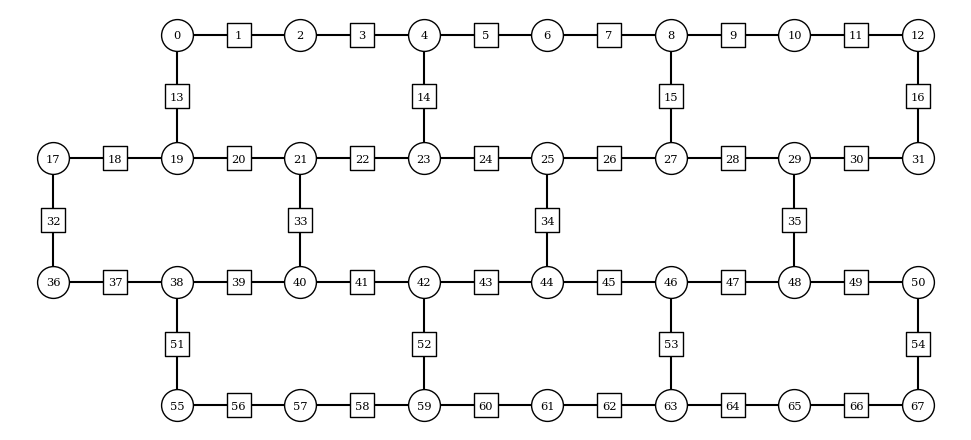

In [ ]:
from z2hex.geometry import HeavyHexLattice
 
plaquette_width = 3
plaquette_height = 7

lattice = HeavyHexLattice(plaquette_width, plaquette_height)
nlayouts = len(lattice.get_all_layouts(backend))
print(f"{nlayouts} possible layouts")
lattice.plot_lattice(number_qubits=True)

# Simulation settings

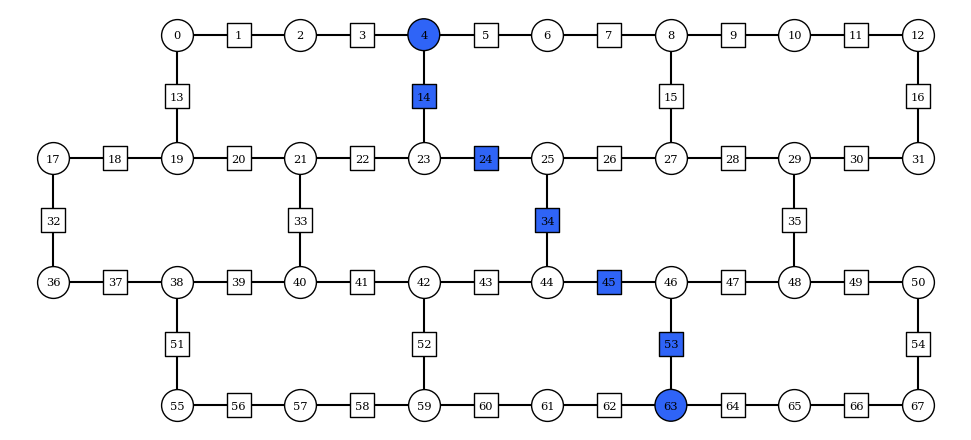

In [ ]:
from z2hex.gdd import zero_mean
from utils.hexec import create_estimator_options
from utils.execrecord import ExecutionRecord
from utils.hexec import ExecDB
from functools import partial

lattice_dims = (plaquette_width, plaquette_height)
J = 5
h = 2
lamb = 1

x_basis = False

fractional_gates = False

# string = [4, 10, 17, 24, 30]
# string = [4, 14, 24, 34, 45, 53, 63]
# string = [21, 33, 41, 52, 62, 72, 83, 91, 103]
# string = [1, 2, 9, 15, 19, 16, 17, 21, 22, 24, 26, 27, 29]
# string = [27, 26, 34, 43, 52, 60, 59]

# string = [19, 20, 33, 41, 52, 62, 72, 83, 91, 104, 111, 124]
string = [27, 26, 24, 22, 33, 41, 43, 45, 53, 64, 62, 60, 71, 79, 81, 83, 91, 102, 100, 98, 109, 117, 119, 121, 122] # Benchmark

final_time = 6
dt = 0.25
steps = 24
desired_error = 1e-2

confidence = 0.7

odr = True
postselect_odr = True
flip_threshold = 1
all_or_first_layout_qubit = None
forbidden_qubits = []
max_layouts = 5
recovery = True
# g_func = None
# g_func = partial(counteract_rotation, ham_param=J)
# g_func = partial(constant, angle=np.pi)
# g_func = random
g_func = zero_mean

pt_num_randomizations = 20
pt_shots_per_randomization = 5000

# shots = pt_num_randomizations * pt_shots_per_randomization
shots = 300000
max_shots = 100000
# max_shots = 10000000
# shots = 75000
# max_shots = 75000
# min_shots = 30000
min_shots = 10000

final_twirl_randomizations = pt_num_randomizations
# if shots > max_shots:
#     final_twirl_randomizations = int(final_twirl_randomizations * max_shots / shots)
# if all_or_first_layout_qubit == True:
#     final_twirl_randomizations = int(final_twirl_randomizations/max_layouts)
# if final_twirl_randomizations < 1:
#     final_twirl_randomizations = 1

sampler_options = {
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": False,
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": True,
        "enable_measure": True,
        "num_randomizations": final_twirl_randomizations,
        "shots_per_randomization": pt_shots_per_randomization
    },
    # "experimental": {
    #     "execution_path": "gen3-turbo"
    # },
}
# execution_database = "z2_hex_jobs_dec.json" # Last db with good jobs / Not in the new order
execution_database = "z2_hex_jobs_after_Madrid.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

execution_record_path = "../../../../Executions_record.xlsx"
execrecord = ExecutionRecord(execution_record_path)

curated_data_folder_path = "Curated data/"

lattice.plot_highlighted_qubits(string, colors=["#2f64f7"]*len(string), number_qubits=True, filepath="z2hex_quench_initial_state.png")

In [14]:
sampler_options

{'default_shots': 300000,
 'execution': {'init_qubits': True, 'meas_type': 'classified'},
 'dynamical_decoupling': {'enable': False, 'sequence_type': 'XY4'},
 'twirling': {'enable_gates': True,
  'enable_measure': True,
  'num_randomizations': 20,
  'shots_per_randomization': 5000}}

# Error guarantees

In [6]:
from z2hex.geometry import HeavyHexLattice
from z2hex.circs import trotter_dt
import numpy as np

lattice = HeavyHexLattice(*lattice_dims)

error_dt = trotter_dt(desired_error, lattice, J, h, lamb)
nsteps = np.ceil(final_time / error_dt)

print(f"To guarantee the desired error, Δt should be:\nΔt = {error_dt:.5f}")
print(f"To correctly reach the desired final time, the number of layers required is:\nN = {nsteps} ({nsteps*6} 2Qb depth)")

To guarantee the desired error, Δt should be:
Δt = 0.01534
To correctly reach the desired final time, the number of layers required is:
N = 261.0 (1566.0 2Qb depth)


In [7]:
from z2hex.circs import trotter_error

lattice = HeavyHexLattice(*lattice_dims)

settings_error = trotter_error(dt, lattice, J, h, lamb)
sim_max_nlayers = np.ceil(final_time // dt + 1).astype(int)

print(f"With the current simultation settings Δt is at most\nΔt = {dt:.5f}")
print(f"The error per layer commited in the wrost case is\nƐ = {settings_error:.05}")
print(f"The number of layers at the final evolution time is\nN = {sim_max_nlayers} ({6*sim_max_nlayers} 2Qb depth)")

With the current simultation settings Δt is at most
Δt = 0.15000
The error per layer commited in the wrost case is
Ɛ = 9.3465
The number of layers at the final evolution time is
N = 27 (162 2Qb depth)


# Circuit generation & observables

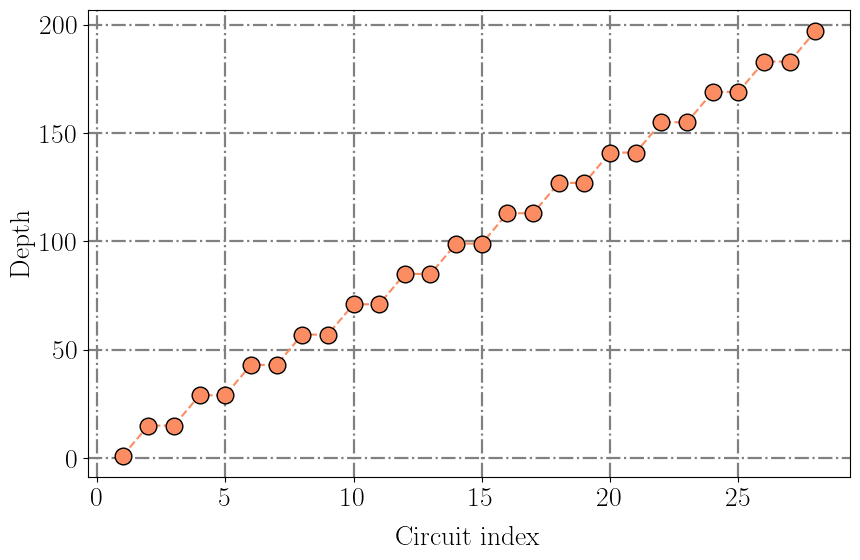

In [15]:
from z2hex.circs import string_quench_simulation_circuits_dt, simulation_and_odr_circuits, get_layouts
from z2hex.geometry import HeavyHexLattice, sort_layouts_by_func, measurement_decoherence_layout_cost
from z2hex.operators import local_pauli_x, local_pauli_z, postselection_operators
from utils.circs import save_many_layout_circs, load_many_layout_circs
from utils.plotting import plot_circuit_arr_depth
from functools import partial
from itertools import product
import numpy as np
import os

optimization_level = 3
barriers = True

lattice = HeavyHexLattice(*lattice_dims)

if all_or_first_layout_qubit == True:
    all_layouts = np.array(get_layouts(lattice, backend, all_or_first_layout_qubit, forbidden_qubits))
    layouts = sort_layouts_by_func(all_layouts, lambda x: measurement_decoherence_layout_cost(x, backend))[:max_layouts]
elif isinstance(all_or_first_layout_qubit, int):
    layouts = [lattice.initial_qubit_layout(first_qubit=all_or_first_layout_qubit, backend=device)]
else:
    layouts = None
circs_args = (lattice, J, h, lamb, string, final_time, dt, steps, backend, optimization_level, g_func, layouts, x_basis, True, barriers)
# "max_shots" option was not present before changing PT
extra_options = {"backend": device, "plaquette_width": lattice_dims[0], "plaquette_height": lattice_dims[1], "J": np.array(J).tolist(), "h": np.array(h).tolist(), "λ":np.array(lamb).tolist(), "g": g_func.__name__ if callable(g_func) else g_func, "string_arr": np.array(string).tolist(), "final_time": final_time, "dt": dt, "steps": steps, "first_qubit": all_or_first_layout_qubit, "x_basis": x_basis, "max_shots": max_shots} | ({"fractional_gates": True} if fractional_gates else {})
# extra_options = {"backend": device, "plaquette_width": lattice_dims[0], "plaquette_height": lattice_dims[1], "J": np.array(J).tolist(), "h": np.array(h).tolist(), "λ":np.array(lamb).tolist(), "g": g_func.__name__ if callable(g_func) else g_func, "string_arr": np.array(string).tolist(), "final_time": final_time, "dt": dt, "steps": steps, "first_qubit": all_or_first_layout_qubit, "x_basis": x_basis} | ({"fractional_gates": True} if fractional_gates else {})
if odr:
    circuits, odr_circuits = simulation_and_odr_circuits(*circs_args)
else:
    circuits = simulation_and_odr_circuits(*circs_args)
observable_generating_funcs = [(lambda nqubits, i=i: local_pauli_z(lattice, i)) for i in range(len(lattice))]
postselection_operators_func = lambda nqubits: postselection_operators(lattice, x_basis=False)

plot_circuit_arr_depth(circuits[0])

In [16]:
circuits[0][-1].count_ops()

OrderedDict([('rz', 7576),
             ('sx', 6140),
             ('cz', 4256),
             ('x', 1246),
             ('measure', 68),
             ('barrier', 29)])

# Load jobs

In [20]:
from utils.postselection_multithreaded import load_postselected_jobs_obs, load_postselected_jobs_inverse_order
import pickle
import os

job_index = 0

overwrite = True
if curated_data_folder_path is not None:
    curated_data_filepath = os.path.join(curated_data_folder_path, f"z2hexquench_curated_data_{device}_px_{lattice_dims[0]}_py_{lattice_dims[1]}_maxt_{final_time}_dt_{dt}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else g_func}_shots_{shots}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string[:10]])}_xbasis_{x_basis}_dd_{sampler_options["dynamical_decoupling"]["enable"]}_pt_{sampler_options["twirling"]["enable_gates"]}_ft_{flip_threshold}_pODR_{postselect_odr}_confidence_{confidence}.pkl")
else:
    curated_data_filepath = ""

if overwrite or not os.path.exists(curated_data_filepath):
    if odr:
        observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts = load_postselected_jobs_obs(job_db, service, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, extra_options=extra_options, odr_circuits=odr_circuits, postselect_odr=postselect_odr, recovery=recovery, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, job_index=job_index, confidence=confidence, return_samples_dicts=True, return_postselected_samples_dicts=True, return_layouts=True, verbose=True, max_shots=max_shots, minimum_shots=min_shots)
    else:
        observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts = load_postselected_jobs_obs(job_db, service, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, extra_options=extra_options, recovery=recovery, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, job_index=job_index, confidence=confidence, return_samples_dicts=True, return_postselected_samples_dicts=True, return_layouts=True, verbose=True, max_shots=max_shots, minimmum_shots=min_shots)
    if curated_data_filepath is not None:
        with open(curated_data_filepath, "wb") as f:
            pickle.dump((observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts), f)
else:
    with open(curated_data_filepath, "rb") as f:
        observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts = pickle.load(f)

Loading jobs...                                                                                    

KeyboardInterrupt: 

In [10]:
curated_data_filepath

'Curated data/z2hexquench_curated_data_ibm_marrakesh_px_2_py_2_maxt_4.5_dt_0.15_steps_30_J_5.0000_h_2.0000_lamb_1.0000_g_zero_mean_shots_300000_fqb_None_string_1-2-9-15-19-16-17-21-22-24_xbasis_False_dd_False_pt_True_ft_1_pODR_True_confidence_0.7.pkl'

In [ ]:
os.path.join(os.getcwd(), curated_data_filepath)

'/Users/cobos/MEGAsync/Doctorado/2nd year/IBM hardware execution/Repo/src/notebooks/Z2/Curated data/z2hexquench_curated_data_ibm_kingston_px_3_py_3_maxt_5_dt_0.15_steps_34_J_0.3000_h_0.5000_lamb_1.0000_g_zero_mean_shots_480000_fqb_None_string_4-14-24-34-45-53-63_xbasis_False_dd_False_pt_True_ft_1_pODR_True_confidence_0.7.pkl'

In [ ]:
len(samples_dicts[0][0][10])

400000

In [ ]:
curated_data_filepath

'Curated data/z2hexquench_curated_data_ibm_kingston_px_3_py_3_maxt_5_dt_0.15_steps_34_J_0.3000_h_0.5000_lamb_1.0000_g_zero_mean_shots_480000_fqb_None_string_4-14-24-34-45-53-63_xbasis_False_dd_False_pt_True_ft_1_pODR_True_confidence_0.7.pkl'

In [ ]:
import os

os.path.abspath(curated_data_filepath)

'/Users/cobos/MEGAsync/Doctorado/2nd year/IBM hardware execution/Repo/src/notebooks/Z2/Curated data/z2hexquench_curated_data_ibm_kingston_px_3_py_3_maxt_5_dt_0.15_steps_34_J_0.3000_h_0.5000_lamb_1.0000_g_zero_mean_shots_480000_fqb_None_string_4-14-24-34-45-53-63_xbasis_False_dd_False_pt_True_ft_1_pODR_True_confidence_0.7.pkl'

## Conserved flips

Total last step postselected samples: 30003


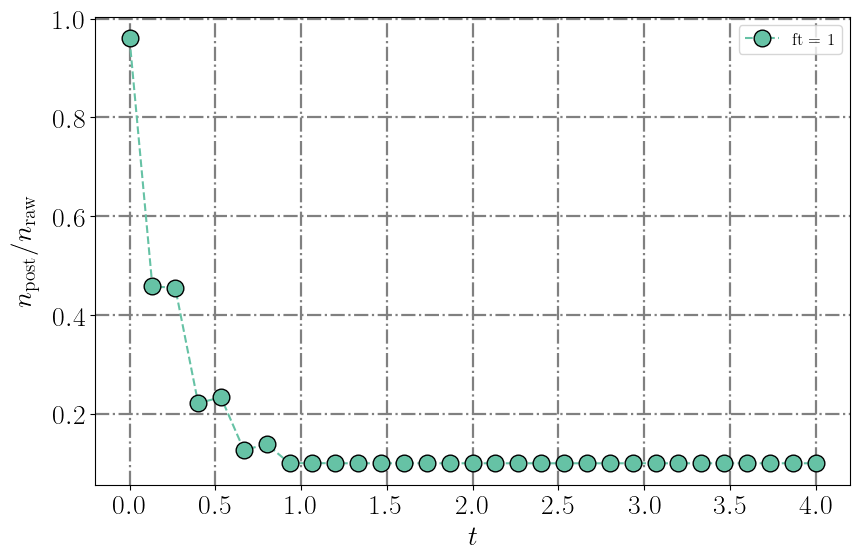

In [14]:
from utils.postselection_multithreaded import multiprocess_layouts_combine_samples_dicts
from utils.plotting import plot_discarded_samples

layout_combined_postselected_samples_dicts = multiprocess_layouts_combine_samples_dicts(postselected_samples_dicts[0])
total_samples = sum(layout_combined_postselected_samples_dicts[-1].values())
print(f"Total last step postselected samples: {total_samples}")

x_ticks = np.round(np.linspace(0, final_time, 6))
x_label = r"$t$"

funclabels = [rf"ft = ${flip_threshold}$"]

plot_filepath = f"z2hex_quench_discarded_samples_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"

plot_discarded_samples([postselected_samples_dicts[0][0]], [samples_dicts[0][0]], x_ticks=x_ticks, x_label=x_label, labels=funclabels, filepath=plot_filepath)

## Flip distribution mean

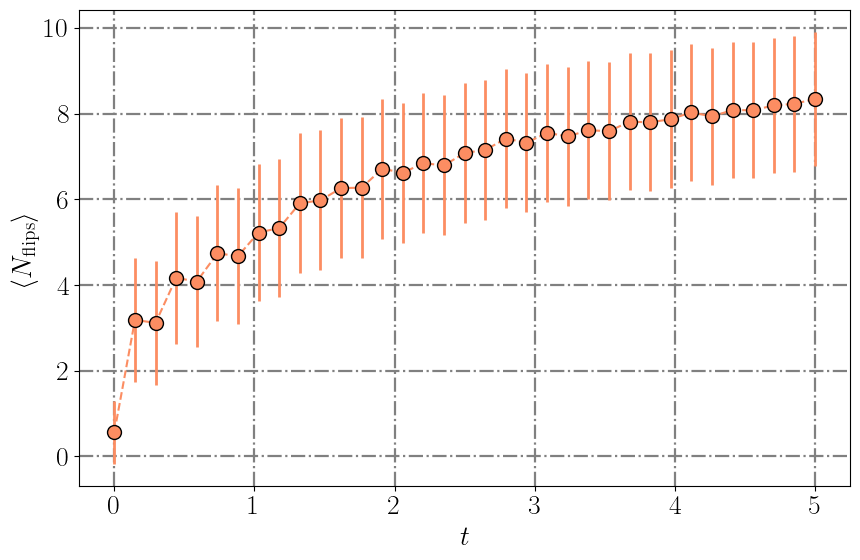

In [16]:
from utils.postselection import initialize_postselection, get_logical_samples_dict, combine_samples_dicts
import matplotlib.pyplot as plt
from pymatching import Matching

plot_filepath = f"z2hex_quench_nflips_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"

postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(len(lattice), postselection_operators_func, observable_generating_funcs)

postselection_mask = np.array([[int(str(opel) == basis) for opel in operator] for operator in postselection_ops])
decoder = Matching(postselection_mask)

distribution_means = np.zeros(steps+1)
standard_distributions = np.zeros(steps+1)
for i in range(steps+1):
    all_layouts_samples_dicts = [samples_dicts[0][j][i] for j in range(len(circuits))]
    combined_samples_dict = combine_samples_dicts(*all_layouts_samples_dicts)
    if combined_samples_dict == {}:
        distribution_means[i] = np.nan
        standard_distributions[i] = np.nan
    else:
        states = np.array([[int(c) for c in string] for string in combined_samples_dict.keys()])
        state_counts = np.array(list(combined_samples_dict.values()))
        states_syndromes = (states @ postselection_mask.T) % 2
        predicted_flips = decoder.decode_batch(states_syndromes)
        nflips = predicted_flips.sum(axis=1)
        unique_nflips = np.unique(nflips)
        this_flip_counts = {}
        this_total_nflips = 0
        for nf in unique_nflips:
            this_counts = np.sum(state_counts[np.equal(nflips, nf)])
            this_flip_counts[nf] = this_counts
            this_total_nflips += this_counts
        this_mean = 0
        for nf, counts in this_flip_counts.items():
            this_mean += nf*counts/this_total_nflips
        distribution_means[i] = this_mean
        for nf, counts in this_flip_counts.items():
            standard_distributions[i] += (nf - this_mean)**2 * counts/this_total_nflips
        standard_distributions[i] = np.sqrt(standard_distributions[i])

plt.rc("text", usetex=True)
plt.rc("font", size=20, family="serif", weight="bold")
fig, ax = plt.subplots(figsize=[9, 6])

x = np.linspace(0, final_time, steps+1)
x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)

plt.errorbar(x, distribution_means, yerr=standard_distributions, fmt="o--", color=plt.get_cmap("Set2")(1), markersize=10, elinewidth=2, markeredgecolor="black")
plt.xlabel(r"$t$")
plt.ylabel(r"$\langle N_{\mathrm{flips}} \rangle$")
plt.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
plt.tight_layout()
plt.savefig(plot_filepath)
plt.rcdefaults()

# Observable plots

## Single frame plots

In [ ]:
from utils.postselection import initialize_postselection, measure_diagonal_observables, get_recovered_postselected_samples_dict
from z2hex.plotting import local_observable_plot, truncate_colormap
import utils.odr as odr

job_index = 10

matter_qb_inds = lattice.node_qbinds

observables_to_plot = observables[0][job_index].copy()
observables_to_plot = (1 - observables_to_plot)/2

local_observable_plot(observables_to_plot, lattice, dark_theme=True, cmap_range_matter=[0, 1], cmap_range_gauge=[0, 1], cmap_label_matter="Matter", cmap_label_gauge="Gauge")

# Animation

In [ ]:
from z2hex.plotting import local_obs_anim, truncate_colormap
from copy import deepcopy

interpolation_frames = 17
fps = 30
frame_to_title_func = lambda frame: f"$t = {final_time * frame / ((interpolation_frames+1)*steps):.02f}$"

cmap_matter = truncate_colormap(plt.get_cmap("pink"), 0, 1)
cmap_gauge = truncate_colormap(plt.get_cmap("RdBu"), 0.1, 0.9)

cmap_range_matter = [0, 1]
cmap_range_gauge = [-1, 1]
cmap_label_matter = r"$(1 - \langle Z \rangle_{\mathrm{matter}})/2$"
cmap_label_gauge = r"$\langle Z \rangle_{\mathrm{gauge}}$"

matter_qb_inds = lattice.node_qbinds
observables_to_plot = deepcopy(observables)
for i, obs in enumerate(observables_to_plot):
    observables_to_plot[i][:, matter_qb_inds] = (1 - obs[:, matter_qb_inds]) / 2

postselected_odr_filepath = f"z2hex_string_quench_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.mp4"
postselected_filepath = f"z2hex_string_quench_nodr_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.mp4"
odr_filepath = f"z2hex_string_quench_odr_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.mp4"
raw_filepath = f"z2hex_string_quench_raw_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.mp4"
local_obs_anim(observables_to_plot[0], lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_matter=cmap_matter, cmap_gauge=cmap_gauge, cmap_range_matter=cmap_range_matter, cmap_label_matter=cmap_label_matter, cmap_label_gauge=cmap_label_gauge, filepath=postselected_odr_filepath, dark_theme=True)
# local_obs_anim(observables_to_plot[1], lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_matter=cmap_matter, cmap_gauge=cmap_gauge, cmap_range_matter=cmap_range_matter, cmap_label_matter=cmap_label_matter, cmap_label_gauge=cmap_label_gauge, filepath=postselected_filepath, dark_theme=True)
# local_obs_anim(observables_to_plot[2], lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_matter=cmap_matter, cmap_gauge=cmap_gauge, cmap_range_matter=cmap_range_matter, cmap_label_matter=cmap_label_matter, cmap_label_gauge=cmap_label_gauge, filepath=odr_filepath, dark_theme=True)
# local_obs_anim(observables_to_plot[3], lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_matter=cmap_matter, cmap_gauge=cmap_gauge, cmap_range_matter=cmap_range_matter, cmap_label_matter=cmap_label_matter, cmap_label_gauge=cmap_label_gauge, filepath=raw_filepath, dark_theme=True)

## String and transversals

### Single qubit plots

#### Select qubits

##### 2x2 (1string)

In [18]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [4, 30]

# qubits = [14]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$ / shots $=$ {total_samples}"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom
legend = False

plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.linspace(0, final_time, 6)

observables_to_plot = observables[0][:, qubits]
observables_stdm = observables_confidence[0][:, qubits]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, title=title, legend=legend, fmt="o--", filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

NameError: name 'total_samples' is not defined

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [14, 20]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$ / shots $=$ {total_samples}"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom
legend = False

plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.linspace(0, final_time, 6)

observables_to_plot = (1 - observables[0][:, qubits]) / 2
observables_stdm = (1 - observables_confidence[0][:, qubits]) / 2

observables_to_plot = observables[0][:, qubits]
observables_stdm = observables_confidence[0][:, qubits]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, title=title, legend=legend, fmt="o--", filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [16, 18]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$ / shots $=$ {total_samples}"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom
legend = False

plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.linspace(0, final_time, 6)

observables_to_plot = (1 - observables[0][:, qubits]) / 2
observables_stdm = (1 - observables_confidence[0][:, qubits]) / 2

observables_to_plot = observables[0][:, qubits]
observables_stdm = observables_confidence[0][:, qubits]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, title=title, legend=legend, fmt="o--", filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [15, 19]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$ / shots $=$ {total_samples}"
y_lim = None # "data" for data limits, None for auto, [,] for custom
legend = False

plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.linspace(0, final_time, 6)

observables_to_plot = observables[0][:, qubits]
observables_stdm = observables_confidence[0][:, qubits]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, title=title, legend=legend, fmt="o--", filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [10, 17, 24]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$ / shots $=$ {total_samples}"
y_lim = None # "data" for data limits, None for auto, [,] for custom
legend = False

plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.linspace(0, final_time, 6)

observables_to_plot = (1 - observables[0][:, qubits]) / 2
observables_stdm = (1 - observables_confidence[0][:, qubits]) / 2

observables_to_plot = observables[0][:, qubits]
observables_stdm = observables_confidence[0][:, qubits]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, title=title, legend=legend, fmt="o--", filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

##### 2x2 (3string)

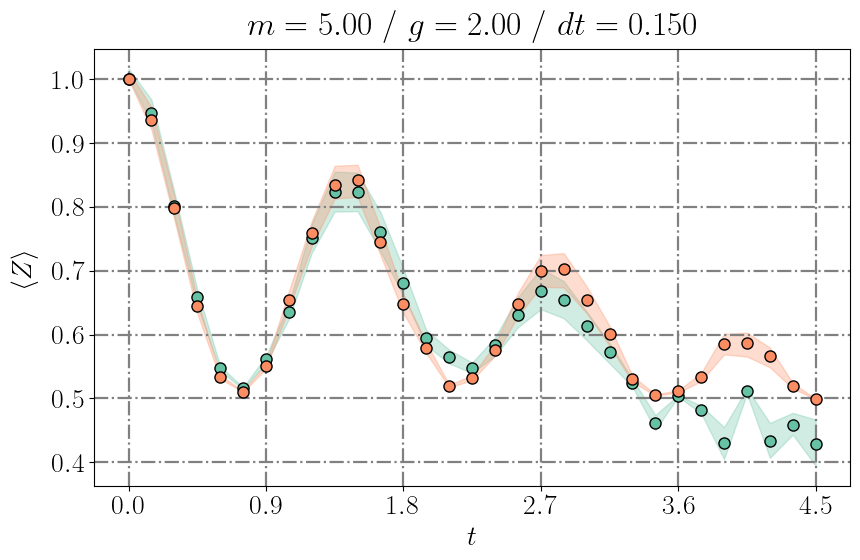

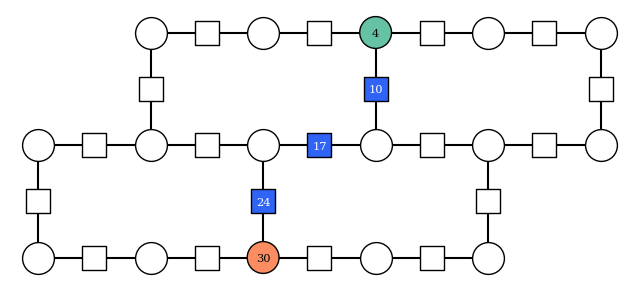

In [17]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [4, 30]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$"
y_lim = None # "data" for data limits, None for auto, [,] for custom
legend = False

plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.linspace(0, final_time, 6)

observables_to_plot = (1 - observables[0][:, qubits]) / 2
observables_stdm = (1 - observables_confidence[0][:, qubits]) / 2

# observables_to_plot = observables[0][:, qubits]
# observables_stdm = observables_confidence[0][:, qubits]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, title=title, legend=legend, fmt="o--", filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [22, 20, 34]
# qubits = [14]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$ / shots $=$ {total_samples}"
y_lim = None # "data" for data limits, None for auto, [,] for custom
legend = False

plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.linspace(0, final_time, 6)

observables_to_plot = observables[0][:, qubits]
observables_stdm = observables_confidence[0][:, qubits]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, title=title, legend=legend, fmt="o--", filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

### Contour plots

In [ ]:
from z2chain.plotting import x_t_separated_plot

# qubits = [6, 5, 4, 10, 18, 17, 16, 24, 30, 29, 28]
qubits = [4, 10, 18, 17, 16, 24, 30]

observables_to_plot = observables[0][:, qubits]
y_ticks = np.linspace(0, final_time, 6)
ylabel = r"$t$"

x_t_separated_plot(observables_to_plot, y_ticks=y_ticks, ylabel=ylabel)

In [ ]:
from z2chain.plotting import x_t_separated_plot

qubits = list(range(14, 21))

observables_to_plot = observables[0][:, qubits]
y_ticks = np.linspace(0, final_time, 6)
ylabel=r"$t$"

x_t_separated_plot(observables_to_plot, y_ticks=y_ticks, ylabel=ylabel, cbar_range_matter=[0, 1])

In [ ]:
from z2chain.plotting import x_t_separated_plot

# qubits = [6, 5, 4, 10, 18, 17, 16, 24, 30, 29, 28]
qubits = [21, 20, 34]

observables_to_plot = observables[0][:, qubits]
y_ticks = np.linspace(0, final_time, 6)
ylabel = r"$t$"

x_t_separated_plot(observables_to_plot, y_ticks=y_ticks, ylabel=ylabel, nxticks=1)

# String projectors configuration

In [ ]:
mk = "0" 
mv = 0
for k, v in postselected_samples_dicts[0][0][0].items():
    if v > mv:
        mk = k
        mv = v

print(mk)
print(mv)

## Projection into single states

In [ ]:
this_string = [2, 1, 9, 15, 17, 19, 21, 22, 26, 27, 29, 31, 32]

lattice.plot_highlighted_qubits(this_string, colors=["#2f64f7"]*len(this_string), number_qubits=True)

In [ ]:
from utils.plotting import plot_string_configuration_evolution
import matplotlib.pyplot as plt
import numpy as np

samples_dicts_to_plot = postselected_samples_dicts[0][0]
string_qubits = [
    string,
    [2, 1, 9, 15, 17, 19, 21, 22, 26, 27, 29, 31, 32],
]

labels = [
    "Initial string (1)",
    "Broken string (20)"
]

cmap = plt.get_cmap("Set2")
x_ticks = np.round(np.linspace(0, np.round(final_time), 6)).astype(int)
x_label = r"$t$"

plot_string_configuration_evolution(samples_dicts_to_plot, string_qubits, x_ticks=x_ticks, labels=labels, x_label=x_label, cmap=cmap)

## Correlators

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
from utils.observables import load_occupation_correlators_bypaulis
import matplotlib.pyplot as plt
import numpy as np

# samples_dicts_to_plot = [postselected_samples_dicts[0][0][19]]
# samples_dicts_to_cal = [postselected_samples_dicts[1][0][19]]

samples_dicts_to_plot = postselected_samples_dicts[0][0]
samples_dicts_to_cal = postselected_samples_dicts[1][0]

occupied_qubits = [
    [4, 30],
    [14, 20],
    # [0, 34],
    # [8, 26],
    # [12, 22]
]

occupation_operators_vals, occupation_operators_confidence = load_occupation_correlators_bypaulis(samples_dicts_to_plot, occupied_qubits, cal_samples_dicts=samples_dicts_to_cal, confidence=0.9, shots=shots)

labels = [
    "-".join([str(i) for i in st]) for st in occupied_qubits
]

cmap = plt.get_cmap("Set2")
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"String correlators"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$"
legend = False

plot_filepath = f"z2hex_quench_occupation_correlators_{"-".join(labels)}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"

qubits = [x for xs in occupied_qubits for x in xs]
to_plot_string_qubits = list(set(string) - set(qubits))
colors = []
for i, s in enumerate(occupied_qubits):
    colors += [cmap(i%8)]*len(s)
colors += ["#2f64f7"]*len(to_plot_string_qubits)

observables_to_plot = occupation_operators_vals[0]
observables_stdm = occupation_operators_confidence[0]

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=y_label, cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, title=title, legend=legend, fmt="o--", filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits, colors=colors)

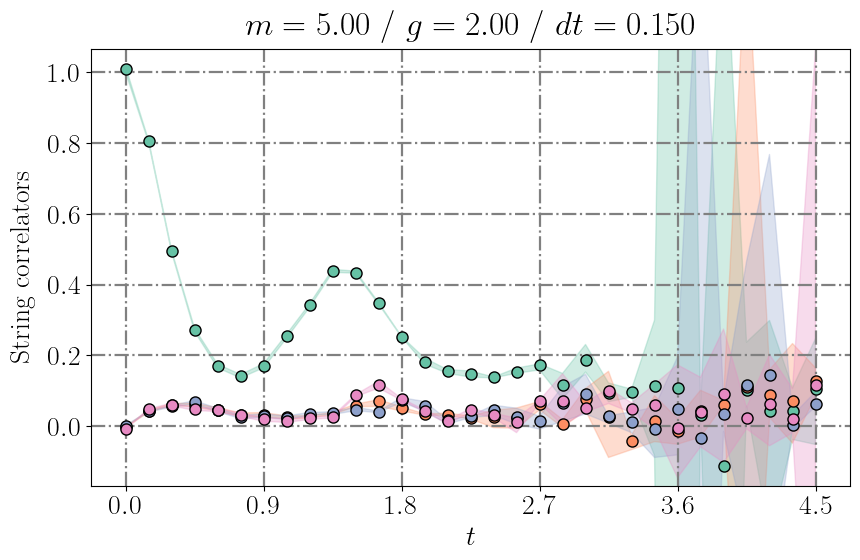

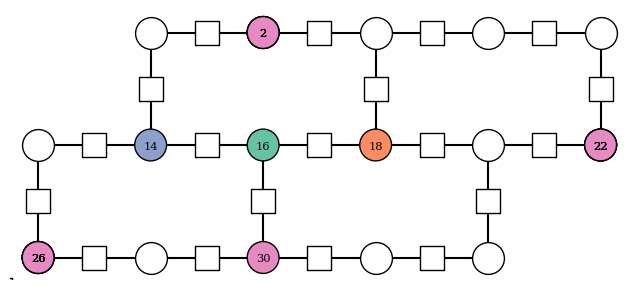

In [17]:
from utils.plotting import plot_individual_qubits_observable_evolution
from utils.observables import load_occupation_correlators_bypaulis
import matplotlib.pyplot as plt
import numpy as np

# samples_dicts_to_plot = [postselected_samples_dicts[0][0][19]]
# samples_dicts_to_cal = [postselected_samples_dicts[1][0][19]]

samples_dicts_to_plot = postselected_samples_dicts[0][0]
samples_dicts_to_cal = postselected_samples_dicts[1][0]

occupied_qubits = [
    [2, 16, 22, 26],
    [2, 18, 22, 26],
    [2, 14, 22, 26],
    [2, 22, 26, 30],
]
# occupied_qubits = [
#     [4, 30],
#     [14, 20]
# ]

occupation_operators_vals, occupation_operators_confidence = load_occupation_correlators_bypaulis(samples_dicts_to_plot, occupied_qubits, cal_samples_dicts=samples_dicts_to_cal, confidence=0.9, shots=shots)

labels = [
    "-".join([str(i) for i in st]) for st in occupied_qubits
]

cmap = plt.get_cmap("Set2")
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"String correlators"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$"
legend = False

plot_filepath = f"z2hex_quench_occupation_correlators_{"-".join(labels)}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"

qubits = [x for xs in occupied_qubits for x in xs]
to_plot_string_qubits = list(set(string) - set(qubits))
colors = []
for i, s in enumerate(occupied_qubits):
    colors += [cmap(i%8)]*len(s)
colors += ["#2f64f7"]*len(to_plot_string_qubits)

observables_to_plot = occupation_operators_vals[0]
observables_stdm = occupation_operators_confidence[0]

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=y_label, cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, title=title, legend=legend, fmt="o--", filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits, colors=colors)

In [15]:
occupation_operators_vals[0].shape

(37, 4)

In [16]:
np.save("hcorrs_new.npy", occupation_operators_vals[0])

In [17]:
np.save("hcorrs_conf_new.npy", occupation_operators_confidence[0])

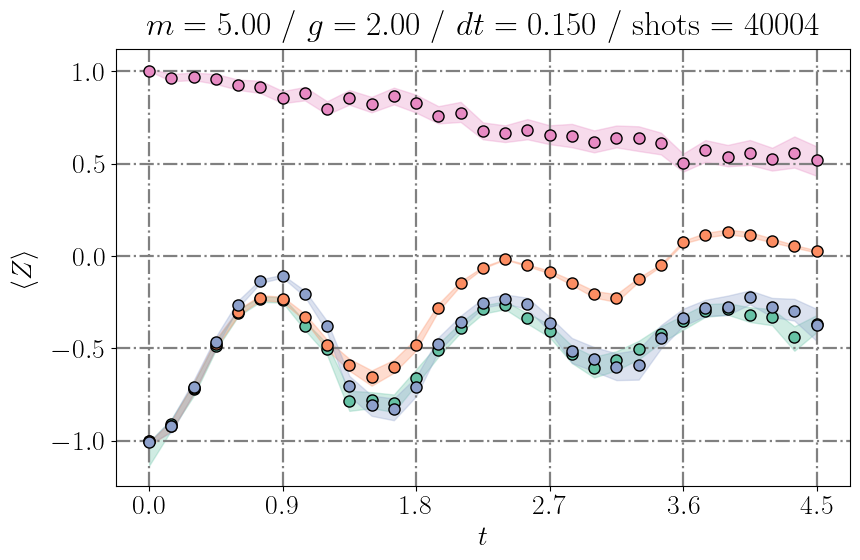

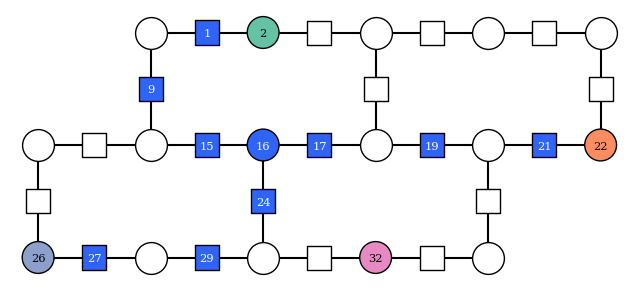

In [12]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [2, 22, 26, 32]
# qubits = [14]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$ / shots $=$ {total_samples}"
y_lim = None # "data" for data limits, None for auto, [,] for custom
legend = False

plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.linspace(0, final_time, 6)

observables_to_plot = observables[0][:, qubits]
observables_stdm = observables_confidence[0][:, qubits]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, title=title, legend=legend, fmt="o--", filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
observables_to_plot[0]

In [ ]:
from utils.plotting import plot_string_configuration_evolution
import matplotlib.pyplot as plt
import numpy as np

samples_dicts_to_plot = postselected_samples_dicts[0][0]
string_qubits = [
    string,
    [4, 10, 18, 16, 24, 30]
]

labels = [
    "-".join([str(i) for i in st]) for st in string_qubits
]

cmap = plt.get_cmap("Set2")
x_ticks = np.round(np.linspace(0, np.round(final_time), 6)).astype(int)
x_label = r"$t$"

plot_string_configuration_evolution(samples_dicts_to_plot, string_qubits, x_ticks=x_ticks, x_label=x_label, cmap=cmap, labels=labels)

#### 3x3 

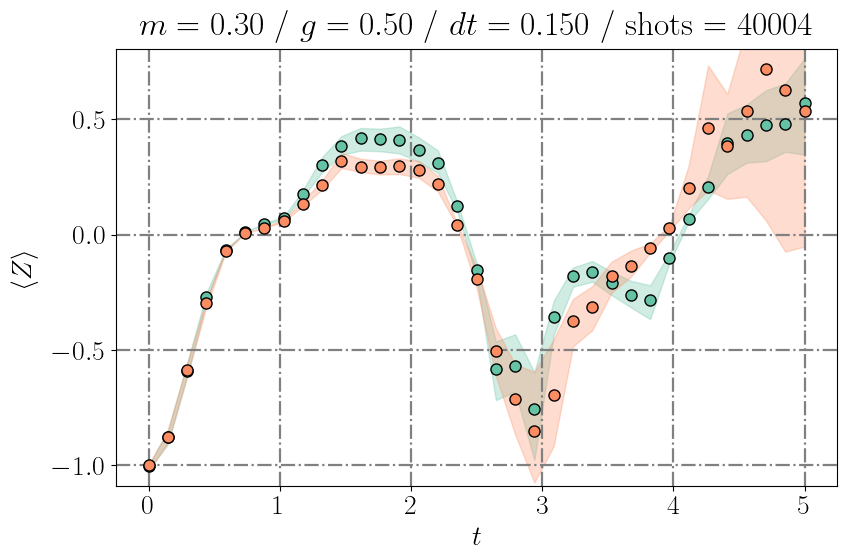

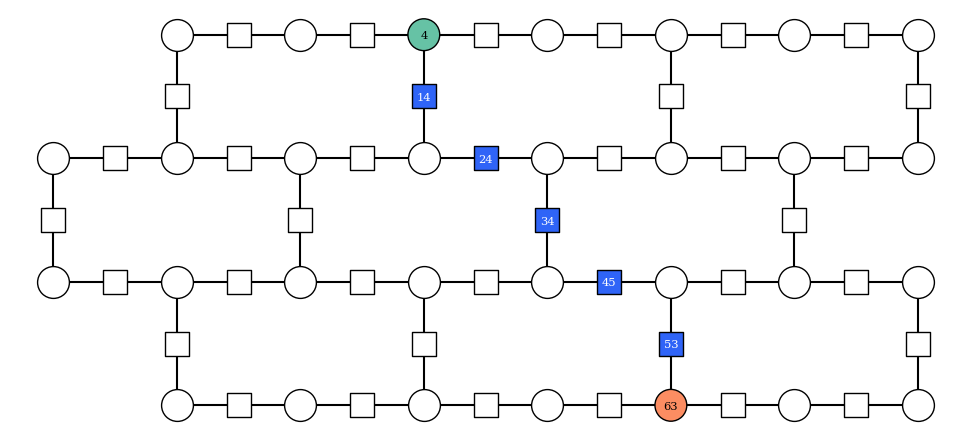

In [33]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [4, 63]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$ / shots $=$ {total_samples}"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom
legend = False

plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.linspace(0, final_time, 6)

observables_to_plot = observables[0][:, qubits]
observables_stdm = observables_confidence[0][:, qubits]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, title=title, legend=legend, fmt="o--", filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

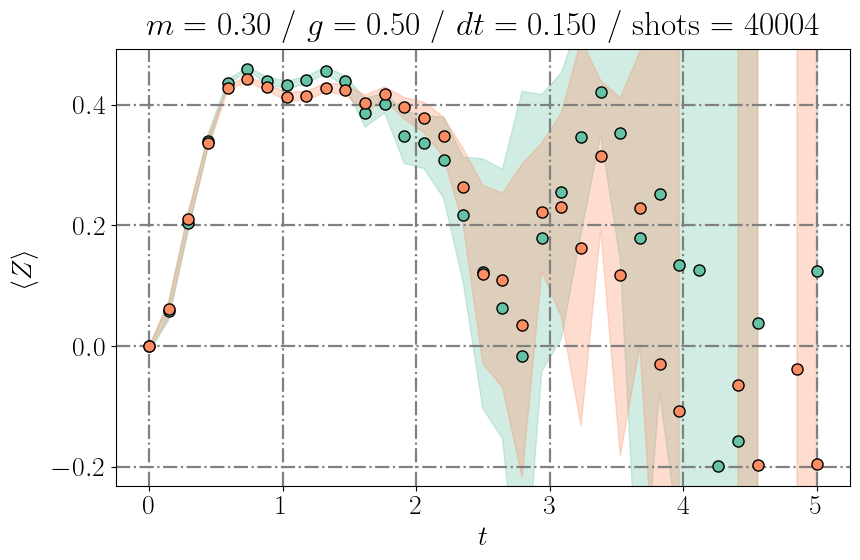

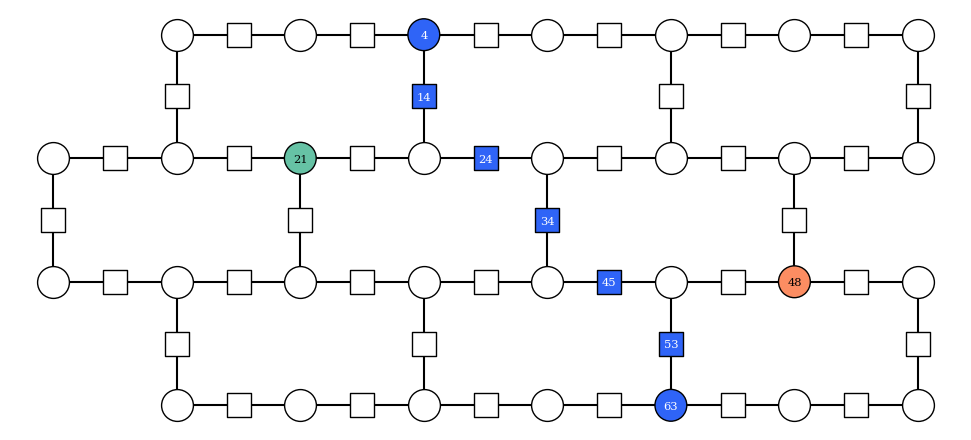

In [34]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [21, 48]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$ / shots $=$ {total_samples}"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom
legend = False

plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.linspace(0, final_time, 6)

observables_to_plot = (1-observables[0][:, qubits])/2
observables_stdm = (1-observables_confidence[0][:, qubits])/2

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, title=title, legend=legend, fmt="o--", filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

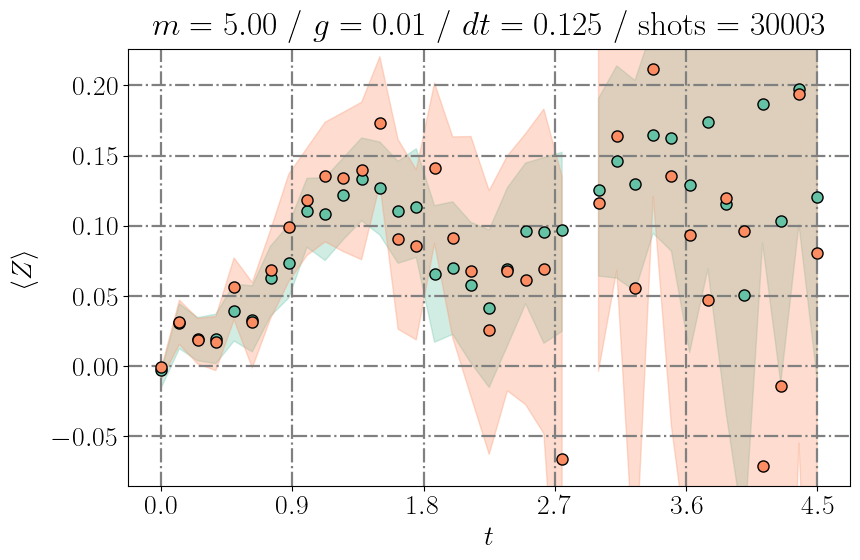

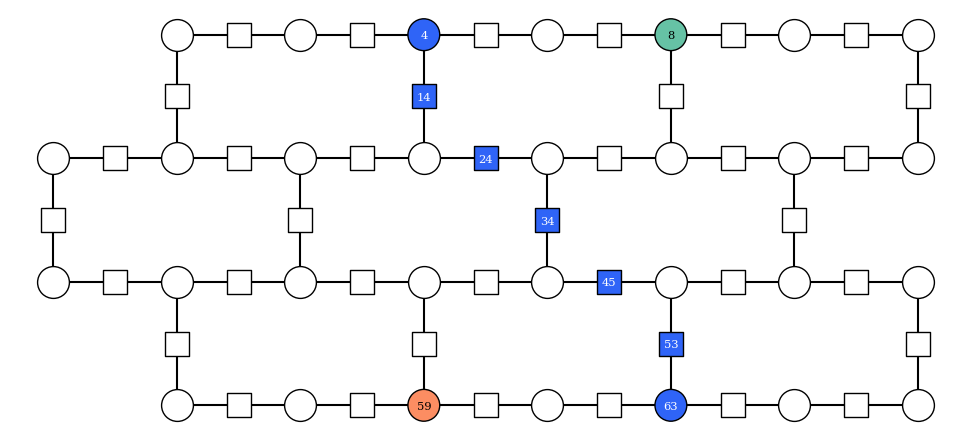

In [14]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [8, 59]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$ / shots $=$ {total_samples}"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom
legend = False

plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.linspace(0, final_time, 6)

observables_to_plot = (1-observables[0][:, qubits])/2
observables_stdm = (1-observables_confidence[0][:, qubits])/2

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, title=title, legend=legend, fmt="o--", filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

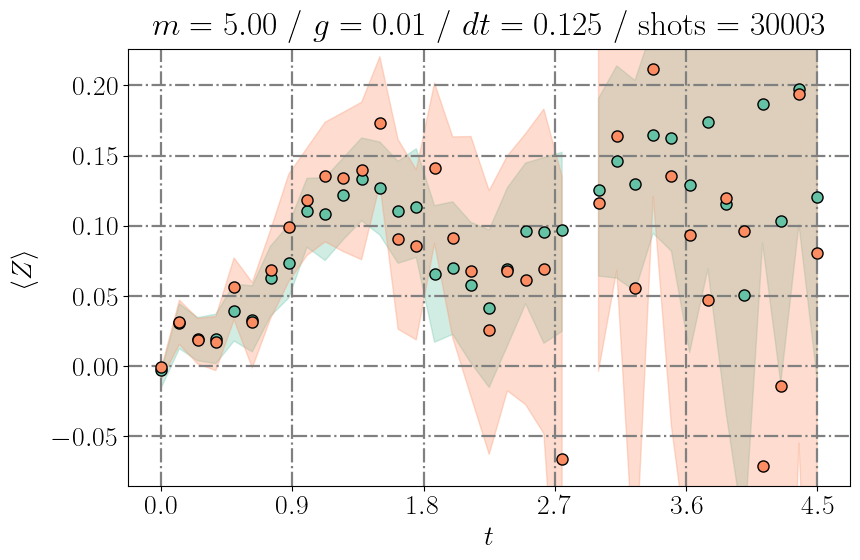

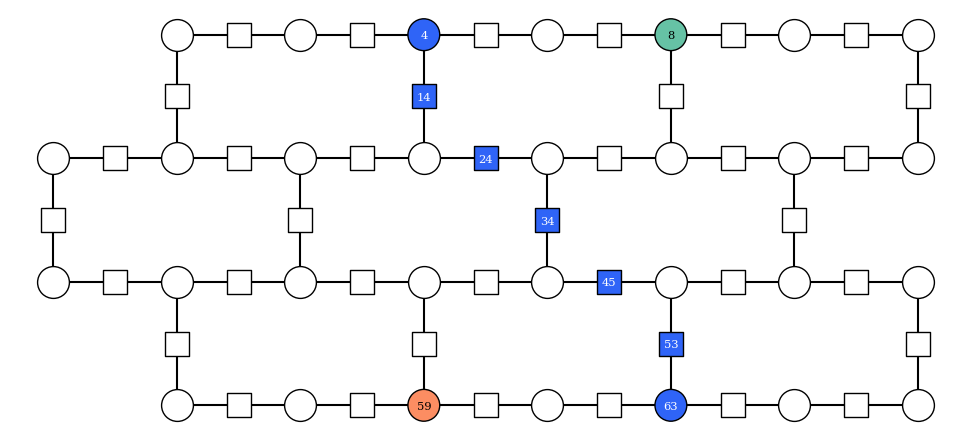

In [15]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [8, 59]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$ / shots $=$ {total_samples}"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom
legend = False

plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.linspace(0, final_time, 6)

observables_to_plot = (1-observables[0][:, qubits])/2
observables_stdm = (1-observables_confidence[0][:, qubits])/2

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, title=title, legend=legend, fmt="o--", filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

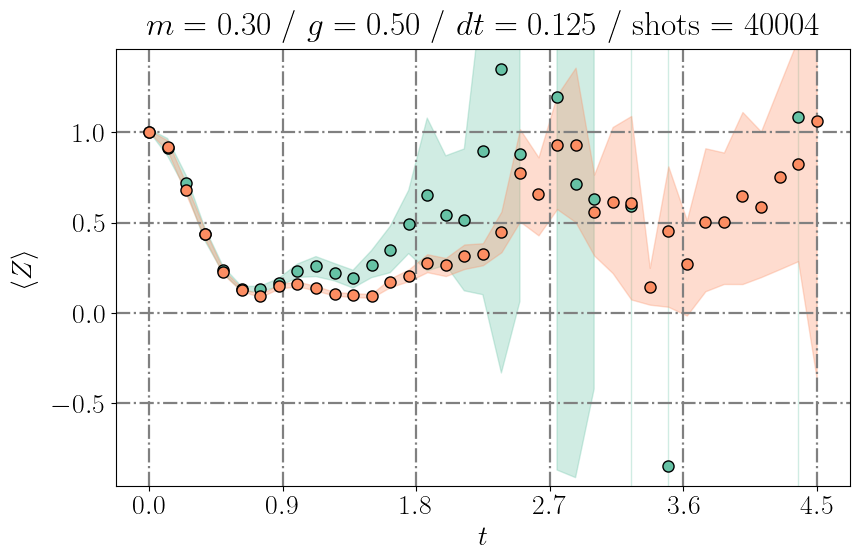

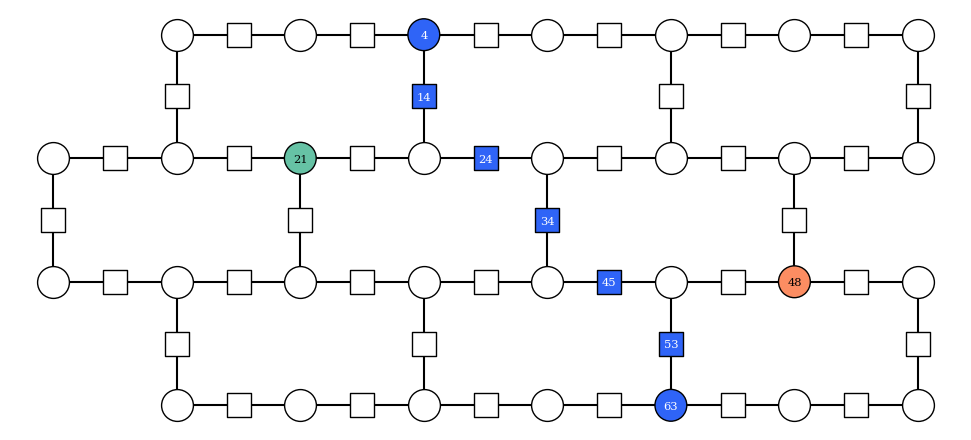

In [17]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [21, 48]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$ / shots $=$ {total_samples}"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom
legend = False

plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.linspace(0, final_time, 6)

observables_to_plot = observables[0][:, qubits]
observables_stdm = observables_confidence[0][:, qubits]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, title=title, legend=legend, fmt="o--", filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

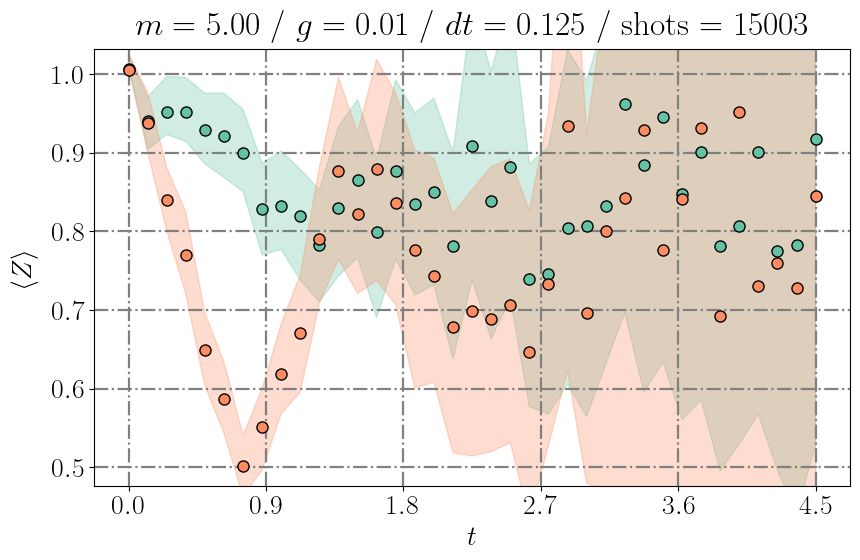

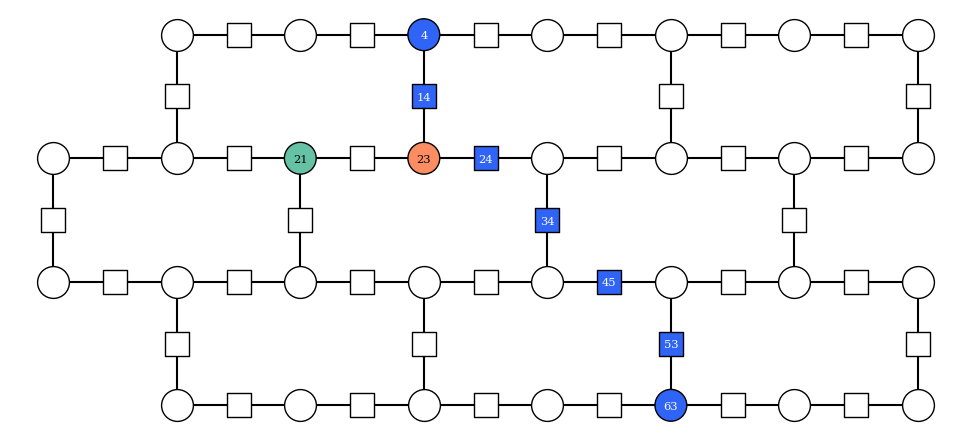

In [17]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [21, 23]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$ / shots $=$ {total_samples}"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom
legend = False

plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.linspace(0, final_time, 6)

observables_to_plot = observables[0][:, qubits]
observables_stdm = observables_confidence[0][:, qubits]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, title=title, legend=legend, fmt="o--", filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

#### 3x4

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [21, 103]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$ / shots $=$ {total_samples}"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom
legend = False

plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.linspace(0, final_time, 6)

observables_to_plot = (1 - observables[0][:, qubits]) / 2
observables_stdm = (1 - observables_confidence[0][:, qubits]) / 2

observables_to_plot = observables[0][:, qubits]
observables_stdm = observables_confidence[0][:, qubits]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, fmt="o--", title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [8, 29, 57, 78]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$ / shots $=$ {total_samples}"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom
legend = False

plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.linspace(0, final_time, 6)

observables_to_plot = (1 - observables[0][:, qubits]) / 2
observables_stdm = (1 - observables_confidence[0][:, qubits]) / 2

observables_to_plot = observables[0][:, qubits]
observables_stdm = observables_confidence[0][:, qubits]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, fmt="o--", title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [23, 63]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$ / shots $=$ {total_samples}"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom
legend = False

plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.linspace(0, final_time, 6)

observables_to_plot = (1 - observables[0][:, qubits]) / 2
observables_stdm = (1 - observables_confidence[0][:, qubits]) / 2

observables_to_plot = observables[0][:, qubits]
observables_stdm = observables_confidence[0][:, qubits]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, fmt="o--", title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [21, 65]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$ / shots $=$ {total_samples}"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom
legend = False

plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.linspace(0, final_time, 6)

observables_to_plot = (1 - observables[0][:, qubits]) / 2
observables_stdm = (1 - observables_confidence[0][:, qubits]) / 2

observables_to_plot = observables[0][:, qubits]
observables_stdm = observables_confidence[0][:, qubits]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, fmt="o--", title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [25, 61]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$ / shots $=$ {total_samples}"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom
legend = False

plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.linspace(0, final_time, 6)

observables_to_plot = (1 - observables[0][:, qubits]) / 2
observables_stdm = (1 - observables_confidence[0][:, qubits]) / 2

observables_to_plot = observables[0][:, qubits]
observables_stdm = observables_confidence[0][:, qubits]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, fmt="o--", title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [44, 42]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$ / shots $=$ {total_samples}"
legend = False

plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.linspace(0, final_time, 6)

observables_to_plot = (1 - observables[0][:, qubits]) / 2
observables_stdm = (1 - observables_confidence[0][:, qubits]) / 2

observables_to_plot = observables[0][:, qubits]
observables_stdm = observables_confidence[0][:, qubits]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, fmt="o--", title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [26, 60]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$ / shots $=$ {total_samples}"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom
legend = False

plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.linspace(0, final_time, 6)

observables_to_plot = (1 - observables[0][:, qubits]) / 2
observables_stdm = (1 - observables_confidence[0][:, qubits]) / 2

observables_to_plot = observables[0][:, qubits]
observables_stdm = observables_confidence[0][:, qubits]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, fmt="o--", title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [34, 52]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$ / shots $=$ {total_samples}"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom
legend = False

plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.linspace(0, final_time, 6)

observables_to_plot = (1 - observables[0][:, qubits]) / 2
observables_stdm = (1 - observables_confidence[0][:, qubits]) / 2

observables_to_plot = observables[0][:, qubits]
observables_stdm = observables_confidence[0][:, qubits]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, fmt="o--", title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [43]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$ / shots $=$ {total_samples}"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom
legend = False

plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.linspace(0, final_time, 6)

observables_to_plot = (1 - observables[0][:, qubits]) / 2
observables_stdm = (1 - observables_confidence[0][:, qubits]) / 2

observables_to_plot = observables[0][:, qubits]
observables_stdm = observables_confidence[0][:, qubits]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, fmt="o--", title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [0, 86]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$ / shots $=$ {total_samples}"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom
legend = False

plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.linspace(0, final_time, 6)

observables_to_plot = (1 - observables[0][:, qubits]) / 2
observables_stdm = (1 - observables_confidence[0][:, qubits]) / 2

observables_to_plot = observables[0][:, qubits]
observables_stdm = observables_confidence[0][:, qubits]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, fmt="o--", title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

### 7 x 4

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [17]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$ / shots $=$ {total_samples}"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom
legend = False

plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.linspace(0, final_time, 6)

observables_to_plot = (1 - observables[0][:, qubits]) / 2
observables_stdm = (1 - observables_confidence[0][:, qubits]) / 2

observables_to_plot = observables[0][:, qubits]
observables_stdm = observables_confidence[0][:, qubits]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, title=title, legend=legend, fmt="o--", filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [18]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$ / shots $=$ {total_samples}"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom
legend = False

plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.linspace(0, final_time, 6)

observables_to_plot = (1 - observables[0][:, qubits]) / 2
observables_stdm = (1 - observables_confidence[0][:, qubits]) / 2

observables_to_plot = observables[0][:, qubits]
observables_stdm = observables_confidence[0][:, qubits]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, title=title, legend=legend, fmt="o--", filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [19]

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$ / shots $=$ {total_samples}"
y_lim = "data" # "data" for data limits, None for auto, [,] for custom
legend = False

plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.linspace(0, final_time, 6)

observables_to_plot = (1 - observables[0][:, qubits]) / 2
observables_stdm = (1 - observables_confidence[0][:, qubits]) / 2

observables_to_plot = observables[0][:, qubits]
observables_stdm = observables_confidence[0][:, qubits]

to_plot_string_qubits = list(set(string) - set(qubits))

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, title=title, legend=legend, fmt="o--", filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits + to_plot_string_qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(to_plot_string_qubits), filepath=legend_filepath)

#### Comparison with Bessel function

In [ ]:
x = np.linspace(0, final_time, steps+1)
function_over(x)

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
from scipy.special import jv
import matplotlib.pyplot as plt
import numpy as np

qubits = [4]

r0 = 1.5
N = 4

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = "String gauge qubit occupations"
legend = False
function_over = lambda x: np.abs(jv(-(N + r0)/2, (2/h*np.sin(h*x)).astype(complex)) + jv((-N + r0)/2, (2/h*np.sin(h*x)).astype(complex)))**2

plot_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.png"
legend_filepath = f"z2hex_quench_qubits_{"-".join([str(qb) for qb in qubits])}_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.png"

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)

observables_to_plot = (1 - observables[0][:, qubits]) / 2
observables_stdm = (1 - observables_confidence[0][:, qubits]) / 2

observables_to_plot = observables[0][:, qubits]
observables_stdm = None

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=function_over, ylabel=r"$\langle Z \rangle$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=None, markers=markers, title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits, colors=[cmap(i%8) for i in range(len(qubits))]+["#2f64f7"]*len(qubits), filepath=legend_filepath)

## 1 Plaquette chain

In [ ]:
[28, 29, 30, 24, 16, 17, 18, 10, 4, 5, 6]

list(range(12, 23))

In [ ]:
from z2chain.plotting import x_t_separated_plot

# reorder = [7, 5, 0, 1, 2, 3, 4, 6, 11, 10, 9, 8]
# qubits = [4, 10, 18, 17, 16, 24, 30]
qubits = [28, 29, 30, 24, 16, 17, 18, 10, 4, 5, 6]

# x_t_separated_plot(observables[0][:, reorder], cbar_range_matter=[0, 1], cbar_range_gauge=[-1, 1])
x_t_separated_plot(observables[0][:, qubits], cbar_range_matter=[0, 1], cbar_range_gauge=[-1, 1])

In [ ]:
from z2chain.plotting import x_t_separated_plot

# reorder = [7, 5, 0, 1, 2, 3, 4, 6, 11, 10, 9, 8]
# qubits = [4, 10, 18, 17, 16, 24, 30]
qubits = [30, 24, 16, 17, 18, 10, 4]

# x_t_separated_plot(observables[0][:, reorder], cbar_range_matter=[0, 1], cbar_range_gauge=[-1, 1])
x_t_separated_plot(observables[0][:, qubits], cbar_range_matter=[0, 1], cbar_range_gauge=[-1, 0])

In [ ]:
from z2chain.plotting import x_t_plot

# reorder = [7, 5, 0, 1, 2, 3, 4, 6, 11, 10, 9, 8]
# qubits = [4, 10, 18, 17, 16, 24, 30]
qubits = [28, 29, 30, 24, 16, 17, 18, 10, 4, 5, 6]

# x_t_separated_plot(observables[0][:, reorder], cbar_range_matter=[0, 1], cbar_range_gauge=[-1, 1])
x_t_plot(1-2*observables[0][:, qubits])

In [ ]:
from z2chain.plotting import x_t_separated_plot

# reorder = [7, 5, 0, 1, 2, 3, 4, 6, 11, 10, 9, 8]
# qubits = [4, 10, 18, 17, 16, 24, 30]
qubits = list(range(14, 21))

# x_t_separated_plot(observables[0][:, reorder], cbar_range_matter=[0, 1], cbar_range_gauge=[-1, 1])
x_t_separated_plot(observables[0][:, qubits], cbar_range_matter=[0, 0.25], cbar_range_gauge=[-1, 1])

In [ ]:
from z2chain.plotting import x_t_separated_plot

reorder = [7, 5, 0, 1, 2, 3, 4, 6, 11, 10, 9, 8]

x_t_separated_plot(observables[1][:, reorder], cbar_range_matter=[0, 1], cbar_range_gauge=[-1, 1])

In [ ]:
from z2chain.plotting import x_t_separated_plot

reorder = [7, 5, 0, 1, 2, 3, 4, 6, 11, 10, 9, 8]

x_t_separated_plot(observables[2][:, reorder], cbar_range_matter=[0, 1], cbar_range_gauge=[-1, 1])

In [ ]:
from z2chain.plotting import x_t_separated_plot

reorder = [7, 5, 0, 1, 2, 3, 4, 6, 11, 10, 9, 8]

x_t_separated_plot(observables[3][:, reorder], cbar_range_matter=[0, 1], cbar_range_gauge=[-1, 1])

##### Many Gauge

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
import matplotlib.pyplot as plt
import numpy as np

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = "String gauge qubit occupations"
legend = False

string_qubit_coords = np.array(lattice.coords)[string]
complete_string_qubit_coords = array_of_coords_to_tuple(lattice.complete_string_with_matter(string_qubit_coords))
matter_complete_string_qubit_coords = [coords for coords in complete_string_qubit_coords if not is_edge_coords(coords)]
gauge_complete_string_qubit_coords = [coords for coords in complete_string_qubit_coords if is_edge_coords(coords)]
matter_complete_string_qubit_qbinds = lattice.coords_to_logical_qb(matter_complete_string_qubit_coords)
gauge_complete_string_qubit_qbinds = lattice.coords_to_logical_qb(gauge_complete_string_qubit_coords)

plot_filepath = f"z2hex_quench_longitudinal_string_gauge_qubits_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_longitudinal_string_gauge_qubits_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)

stdm = (1 - observables_confidence[0][:, gauge_complete_string_qubit_qbinds, :])/2

plot_individual_qubits_observable_evolution((1 - observables[0][:, gauge_complete_string_qubit_qbinds])/2, observable_confidence_matrix=stdm, ylabel=r"$(1 - \langle Z \rangle)/2$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=[-0.05, 1.05], markers=markers, title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(gauge_complete_string_qubit_qbinds + matter_complete_string_qubit_qbinds, colors=[cmap(i%8) for i in range(len(gauge_complete_string_qubit_qbinds))]+["#2f64f7"]*len(matter_complete_string_qubit_qbinds), filepath=legend_filepath)

##### Matter

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
import matplotlib.pyplot as plt
import numpy as np

cmap = lambda x: plt.get_cmap("Set2")((x+2)%8)
markers = None #["v", "^"]
title = "String matter qubit occupations"
legend = False

string_qubit_coords = np.array(lattice.coords)[string]
complete_string_qubit_coords = array_of_coords_to_tuple(lattice.complete_string_with_matter(string_qubit_coords))
matter_complete_string_qubit_coords = [coords for coords in complete_string_qubit_coords if not is_edge_coords(coords)]
gauge_complete_string_qubit_coords = [coords for coords in complete_string_qubit_coords if is_edge_coords(coords)]
matter_complete_string_qubit_qbinds = lattice.coords_to_logical_qb(matter_complete_string_qubit_coords)
gauge_complete_string_qubit_qbinds = lattice.coords_to_logical_qb(gauge_complete_string_qubit_coords)

plot_filepath = f"z2hex_quench_longitudinal_string_matter_qubits_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_longitudinal_string_matter_qubits_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)

stdm = (1 - observables_confidence[0][:, matter_complete_string_qubit_qbinds, :])/2

plot_individual_qubits_observable_evolution((1 - observables[0][:, matter_complete_string_qubit_qbinds])/2, observable_confidence_matrix=stdm, ylabel=r"$(1 - \langle Z \rangle)/2$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=[-0.05, 1.05], markers=markers, title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(matter_complete_string_qubit_qbinds + gauge_complete_string_qubit_qbinds, colors=[cmap(i%8) for i in range(len(matter_complete_string_qubit_qbinds))] + ["#2f64f7"]*len(gauge_complete_string_qubit_qbinds), filepath=legend_filepath)

### Mean between qubits

##### Gauge & Matter

In [ ]:
from utils.plotting import plot_average_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
import matplotlib.pyplot as plt
import numpy as np

cmap = lambda x: plt.get_cmap("Set2")(2*x)
markers = None #["v", "^"]
title = r"String gauge \& matter mean qubit occupations"
legend = True

string_qubit_coords = np.array(lattice.coords)[string]
complete_string_qubit_coords = array_of_coords_to_tuple(lattice.complete_string_with_matter(string_qubit_coords))
matter_complete_string_qubit_coords = [coords for coords in complete_string_qubit_coords if not is_edge_coords(coords)]
gauge_complete_string_qubit_coords = [coords for coords in complete_string_qubit_coords if is_edge_coords(coords)]
matter_complete_string_qubit_qbinds = lattice.coords_to_logical_qb(matter_complete_string_qubit_coords)
gauge_complete_string_qubit_qbinds = lattice.coords_to_logical_qb(gauge_complete_string_qubit_coords)
qubits_to_average = [gauge_complete_string_qubit_qbinds, matter_complete_string_qubit_qbinds]

plot_filepath = f"z2hex_quench_longitudinal_string_gauge_mean_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_longitudinal_string_gauge_mean_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)
labels = ["Gauge", "Matter"]

plot_average_qubits_observable_evolution((1-observables[0])/2, qubits_to_average, observable_confidence_matrix=(1-observables_confidence[0])/2, ylabel=r"$(1 - \langle Z \rangle)/2$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_ticks=[0, 0.25, 0.5, 0.75, 1], y_lim=[-0.05, 1.05], markers=markers, title=title, funclabels=labels, legend=legend, filepath=plot_filepath)
lattice.plot_lines_of_qubits(qubits_to_average, colors=[cmap(i%8) for i in range(len(qubits_to_average))], join_lines=[False, False], filepath=legend_filepath) 

## String transversals

### Individual qubit plots

#### Gauge

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
import matplotlib.pyplot as plt
import numpy as np

cmap = lambda x: plt.get_cmap("Set2")(x)
markers = None #["v", "^"]
title = "String transversal gauge qubit occupations"
legend = False

start_coords = lattice.coords[5]
angle = -1
transversal_gauge_qubits = lattice.line_of_qubits(lattice.coords_to_logical_qb(start_coords), angle)
sliced_observable = observables[0][:, transversal_gauge_qubits]
sliced_observable_confidence = observables_confidence[0][:, transversal_gauge_qubits]
clean_string = [qb for qb in string if qb not in transversal_gauge_qubits]

plot_filepath = f"z2hex_quench_transversal_string_gauge_qubits_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_transversal_string_gauge_qubits_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

plot_individual_qubits_observable_evolution((1 - sliced_observable)/2, observable_confidence_matrix=None, ylabel=r"$(1 - \langle Z \rangle)/2$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=[-0.05, 1.05], markers=markers, title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(transversal_gauge_qubits + clean_string, colors=[cmap(i) for i in range(len(transversal_gauge_qubits))]+["#2f64f7"]*len(clean_string), filepath=legend_filepath)

#### Matter

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
import matplotlib.pyplot as plt

cmap = lambda x: plt.get_cmap("Set2")((2+x)%8)
markers = None #["v", "^"]
title = "String transversal matter qubit occupations"
legend = False

# middle_qubit_coord = lattice.coords[string[len(string)//2]]
# complete_string_coords = array_of_coords_to_tuple(lattice.complete_string_with_matter(string))
# transversal_matter_qubits = []
# for coords in complete_string_coords:
#     if not is_edge_coords(coords):
#         dx = coords[1] - middle_qubit_coord[1]
#         mirror_coords = (coords[0], middle_qubit_coord[1] - dx)
#         transversal_matter_qubits.append(lattice.coords_to_logical_qb(mirror_coords))

transversal_matter_qubits = [10, 27, 44, 61, 78, 95, 112]
sliced_observable = observables[0][:, transversal_matter_qubits]

plot_filepath = f"z2hex_quench_transversal_1_string_matter_qubits_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_transversal_1_string_matter_qubits_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"
clean_string = [qb for qb in string if qb not in transversal_matter_qubits]

confidence = (1 - observables_confidence[0][:, transversal_matter_qubits, :])/2

plot_individual_qubits_observable_evolution((1 - sliced_observable)/2, observable_confidence_matrix=confidence, ylabel=r"$(1 - \langle Z \rangle)/2$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", markers=markers, y_lim=[-0.05, 1.05], title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(transversal_matter_qubits + clean_string, colors=[cmap(i) for i in range(len(transversal_matter_qubits))]+["#2f64f7"]*len(clean_string), filepath=legend_filepath)

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
import matplotlib.pyplot as plt

cmap = lambda x: plt.get_cmap("Set2")(x)
markers = None #["v", "^"]
title = "String transversal matter qubit occupations"
legend = False

# middle_qubit_coord = lattice.coords[string[len(string)//2]]
# complete_string_coords = array_of_coords_to_tuple(lattice.complete_string_with_matter(string))
# transversal_matter_qubits = []
# for coords in complete_string_coords:
#     if not is_edge_coords(coords):
#         dx = coords[1] - middle_qubit_coord[1]
#         mirror_coords = (coords[0], middle_qubit_coord[1] - dx)
#         transversal_matter_qubits.append(lattice.coords_to_logical_qb(mirror_coords))

transversal_matter_qubits = [12, 14, 16, 18, 20, 22]
sliced_observable = observables[0][:, transversal_matter_qubits]

plot_filepath = f"z2hex_quench_transversal_2_string_matter_qubits_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_transversal_2_string_matter_qubits_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"
clean_string = [qb for qb in string if qb not in transversal_gauge_qubits]

confidence = (1 - observables_confidence[0][:, transversal_matter_qubits, :])/2

plot_individual_qubits_observable_evolution((1 - sliced_observable)/2, observable_confidence_matrix=confidence, ylabel=r"$(1 - \langle Z \rangle)/2$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=[-0.05, 1.05], markers=markers, title=title,  legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(transversal_matter_qubits + clean_string, colors=[cmap(i) for i in range(len(transversal_matter_qubits))]+["#2f64f7"]*len(clean_string), filepath=legend_filepath)

## Extremum oscillations

#### Top end (Gauge)

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt
import numpy as np

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = "Top end gauge oscillations"
legend = False

string_qubit_coords = np.array(lattice.coords)[string]
to_plot_qubit_coord_candidates = []

for axisdir in [(0, 0.5), (0, -0.5), (0.5, 0)]:
    candidate = string_qubit_coords[0] + np.array(axisdir)
    if tuple(candidate.tolist()) in lattice.coords:
        to_plot_qubit_coord_candidates.append(candidate)

to_plot_qubit_inds = lattice.coords_to_logical_qb(to_plot_qubit_coord_candidates)

sliced_observable = observables[0][:, to_plot_qubit_inds]
sliced_observable_confidence = observables_confidence[0][:, to_plot_qubit_inds, :]
plot_filepath = f"z2hex_quench_top_end_gauge_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_top_end_gauge_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)
funclabels = [r"$q_{%d}$" % i for i in to_plot_qubit_inds]

clean_string = [qb for qb in string if qb not in to_plot_qubit_inds]

plot_individual_qubits_observable_evolution((1-sliced_observable)/2, (1 - sliced_observable_confidence)/2, r"$(1 - \langle Z \rangle)/2$", cmap=cmap, markers=markers, x_ticks=x_ticks, x_label="$t$", y_lim=[-0.05, 1.05], funclabels=funclabels, title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(to_plot_qubit_inds + clean_string, colors=[cmap(0), cmap(1), cmap(2)]+["#2f64f7"]*len(clean_string), filepath=legend_filepath)

#### Top end (Matter)

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt
import numpy as np

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = "Top end matter oscillations"
legend = False

string_qubit_coords = np.array(lattice.coords)[string]
to_plot_qubit_coord_candidates = []

for axisdir in [(0, 0), (0, 1), (0, -1), (1, 0)]:
    candidate = string_qubit_coords[0] + np.array(axisdir)
    if tuple(candidate.tolist()) in lattice.coords:
        to_plot_qubit_coord_candidates.append(candidate)

to_plot_qubit_inds = lattice.coords_to_logical_qb(to_plot_qubit_coord_candidates)

# to_plot_qubit_inds = [25, 27, 29]

sliced_observable = observables[0][:, to_plot_qubit_inds]
sliced_observable_confidence = observables_confidence[0][:, to_plot_qubit_inds, :]
plot_filepath = f"z2hex_quench_top_end_matter_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_top_end_matter_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)
funclabels = [r"$q_{%d}$" % i for i in to_plot_qubit_inds]

clean_string = [qb for qb in string if qb not in to_plot_qubit_inds]

plot_individual_qubits_observable_evolution((1-sliced_observable)/2, (1 - sliced_observable_confidence)/2, r"$(1 - \langle Z \rangle)/2$", cmap=cmap, markers=markers, x_ticks=x_ticks, x_label="$t$", y_lim=[-0.05, 1.05], funclabels=funclabels, title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(to_plot_qubit_inds + clean_string, colors=[cmap(0), cmap(1), cmap(2), cmap(3)]+["#2f64f7"]*len(clean_string), filepath=legend_filepath)

#### Bottom end (Gauge)

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt
import numpy as np

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = "Bottom end gauge oscillations"
legend = False

string_qubit_coords = np.array(lattice.coords)[string]
to_plot_qubit_coord_candidates = []

for axisdir in [(0, 0.5), (0, -0.5), (-0.5, 0)]:
    candidate = string_qubit_coords[-1] + np.array(axisdir)
    if tuple(candidate.tolist()) in lattice.coords:
        to_plot_qubit_coord_candidates.append(candidate)

to_plot_qubit_inds = lattice.coords_to_logical_qb(to_plot_qubit_coord_candidates)

# to_plot_qubit_inds = [25, 27, 29]

sliced_observable = observables[0][:, to_plot_qubit_inds]
sliced_observable_confidence = observables_confidence[0][:, to_plot_qubit_inds, :]
plot_filepath = f"z2hex_quench_bottom_end_gauge_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_bottom_end_gauge_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)
funclabels = [r"$q_{%d}$" % i for i in to_plot_qubit_inds]

clean_string = [qb for qb in string if qb not in to_plot_qubit_inds]

plot_individual_qubits_observable_evolution((1-sliced_observable)/2, (1 - sliced_observable_confidence)/2, r"$(1 - \langle Z \rangle)/2$", cmap=cmap, markers=markers, x_ticks=x_ticks, x_label="$t$", y_lim=[-0.05, 1.05], funclabels=funclabels, title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(to_plot_qubit_inds + clean_string, colors=[cmap(0), cmap(1), cmap(2)]+["#2f64f7"]*len(clean_string), filepath=legend_filepath)

#### Bottom end (Matter)

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt
import numpy as np

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = "Bottom end matter oscillations"
legend = False

string_qubit_coords = np.array(lattice.coords)[string]
to_plot_qubit_coord_candidates = []

for axisdir in [(0, 0), (0, 1), (0, -1), (-1, 0)]:
    candidate = string_qubit_coords[-1] + np.array(axisdir)
    if tuple(candidate.tolist()) in lattice.coords:
        to_plot_qubit_coord_candidates.append(candidate)
        
to_plot_qubit_inds = lattice.coords_to_logical_qb(to_plot_qubit_coord_candidates)

sliced_observable = observables[0][:, to_plot_qubit_inds]
sliced_observable_confidence = observables_confidence[0][:, to_plot_qubit_inds, :]
plot_filepath = f"z2hex_quench_bottom_end_matter_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_bottom_end_matter_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)
funclabels = [r"$q_{%d}$" % i for i in to_plot_qubit_inds]

clean_string = [qb for qb in string if qb not in to_plot_qubit_inds]

plot_individual_qubits_observable_evolution((1-sliced_observable)/2, (1 - sliced_observable_confidence)/2, r"$(1 - \langle Z \rangle)/2$", cmap=cmap, markers=markers, x_ticks=x_ticks, x_label="$t$", y_lim=[-0.05, 1.05], funclabels=funclabels, title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(to_plot_qubit_inds + clean_string, colors=[cmap(0), cmap(1), cmap(2), cmap(3)]+["#2f64f7"]*len(clean_string), filepath=legend_filepath)

## String plots

#### Left gauge covering plots

In [ ]:
from utils.plotting import plot_average_qubits_observable_evolution
from z2hex.geometry import is_edge_coords, array_of_coords_to_tuple
import matplotlib.pyplot as plt
import numpy as np

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = "Left gauge covering occupations"

string_qubit_coords_arr = np.array(lattice.coords)[string]
string_qubit_coords_tup = array_of_coords_to_tuple(string_qubit_coords_arr)
complete_string_qubit_coords = lattice.complete_string_with_matter(string_qubit_coords_arr)
qubits_to_average = []
for displacement in [-1, -2]:
    this_displacement_coords = []
    for scoords in complete_string_qubit_coords:
        scoords = array_of_coords_to_tuple(scoords)
        if not is_edge_coords(scoords):
            matter_reference = (scoords[0], scoords[1] + displacement + 1)
            candidates = [(matter_reference[0] - 0.5, matter_reference[1]), (matter_reference[0], matter_reference[1] - 0.5), (matter_reference[0] + 0.5, matter_reference[1])]
            for candidate in candidates:
                if candidate in lattice.coords and (candidate not in string_qubit_coords_tup):
                    if len(this_displacement_coords) == 0:
                        this_displacement_coords.append(candidate)
                    else:
                        if candidate[0] not in [c[0] for c in this_displacement_coords]:
                            this_displacement_coords.append(candidate)
    qubits_to_average.append(lattice.coords_to_logical_qb(this_displacement_coords))

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)
qubits_to_highlight = qubits_to_average + [string]

plot_filepath = f"z2hex_quench_left_cover_gauge_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_left_cover_gauge_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

plot_average_qubits_observable_evolution((1-observables[0])/2, qubits_to_average, observable_confidence_matrix=(1-observables_confidence[0])/2, markers=markers, x_ticks=x_ticks, x_label=r"$t$", y_lim=[-0.05, 1.05], title=title, filepath=plot_filepath)
lattice.plot_lines_of_qubits(qubits_to_highlight, colors=[cmap(0), cmap(1), "#2f64f7"], join_lines=[True, True, False], filepath=legend_filepath)

#### Right gauge covering plots

In [ ]:
from utils.plotting import plot_average_qubits_observable_evolution
from z2hex.geometry import is_edge_coords, array_of_coords_to_tuple
import matplotlib.pyplot as plt
import numpy as np

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = "Right gauge covering occupations"

string_qubit_coords_arr = np.array(lattice.coords)[string]
string_qubit_coords_tup = array_of_coords_to_tuple(string_qubit_coords_arr)
complete_string_qubit_coords = lattice.complete_string_with_matter(string_qubit_coords_arr)
complete_string_qubit_coords_tup = array_of_coords_to_tuple(complete_string_qubit_coords)
qubits_to_average = []
for displacement in [1, 2]:
    this_displacement_coords = []
    for scoords in complete_string_qubit_coords:
        scoords = array_of_coords_to_tuple(scoords)
        if not is_edge_coords(scoords):
            matter_reference = (scoords[0], scoords[1] + displacement)
            if (scoords[0], scoords[1] + 1) in complete_string_qubit_coords_tup:
                continue
            candidates = [(matter_reference[0], matter_reference[1] - 0.5), (matter_reference[0] + 0.5, matter_reference[1])]
            for candidate in candidates:
                if candidate in lattice.coords and (candidate not in string_qubit_coords_tup):
                    if len(this_displacement_coords) == 0:
                        this_displacement_coords.append(candidate)
                    else:
                        if candidate[0] not in [c[0] for c in this_displacement_coords]:
                            this_displacement_coords.append(candidate)
    qubits_to_average.append(lattice.coords_to_logical_qb(this_displacement_coords))

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)
qubits_to_highlight = qubits_to_average + [string]

plot_filepath = f"z2hex_quench_right_cover_gauge_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_right_cover_gauge_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

plot_average_qubits_observable_evolution((1-observables[0])/2, qubits_to_average, observable_confidence_matrix=(1-observables_confidence[0])/2, markers=markers, x_ticks=x_ticks, x_label=r"$t$", y_lim=[-0.05, 1.05], title=title, filepath=plot_filepath)
lattice.plot_lines_of_qubits(qubits_to_highlight, colors=[cmap(0), cmap(1), "#2f64f7"], join_lines=[True, True, False], filepath=legend_filepath)

#### Left matter covering plots

In [ ]:
from utils.plotting import plot_average_qubits_observable_evolution
from z2hex.geometry import is_edge_coords, array_of_coords_to_tuple
import matplotlib.pyplot as plt
import numpy as np

cmap = lambda x: plt.get_cmap("Set2")(x+2)
markers = None #["v", "^"]
title = "Left matter covering occupations"
legend = False

string_qubit_coords_arr = np.array(lattice.coords)[string]
string_qubit_coords_tup = array_of_coords_to_tuple(string_qubit_coords_arr)
complete_string_qubit_coords = lattice.complete_string_with_matter(string_qubit_coords_arr)
complete_string_qubit_coords_tup = array_of_coords_to_tuple(complete_string_qubit_coords)
qubits_to_average = []
for displacement in [-1, -2]:
    this_displacement_coords = []
    for scoords in complete_string_qubit_coords:
        scoords = array_of_coords_to_tuple(scoords)
        if not is_edge_coords(scoords):
            candidate = (scoords[0], scoords[1] + displacement)
            if candidate in complete_string_qubit_coords_tup:
                continue
            if candidate in lattice.coords and (candidate not in string_qubit_coords_tup):
                if len(this_displacement_coords) == 0:
                    this_displacement_coords.append(candidate)
                else:
                    if candidate[0] not in [c[0] for c in this_displacement_coords]:
                        this_displacement_coords.append(candidate)
    qubits_to_average.append(lattice.coords_to_logical_qb(this_displacement_coords))

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)
qubits_to_highlight = qubits_to_average + [string]

plot_filepath = f"z2hex_quench_left_cover_matter_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_left_cover_matter_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

plot_average_qubits_observable_evolution((1-observables[0])/2, qubits_to_average, observable_confidence_matrix=(1-observables_confidence[0])/2, markers=markers, cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=[-0.05, 1.05], title=title, legend=legend, filepath=plot_filepath)
lattice.plot_lines_of_qubits(qubits_to_highlight, colors=[cmap(0), cmap(1), "#2f64f7"], join_lines=[True, True, False], filepath=legend_filepath)

#### Right matter covering plots

In [ ]:
from utils.plotting import plot_average_qubits_observable_evolution
from z2hex.geometry import is_edge_coords, array_of_coords_to_tuple
import matplotlib.pyplot as plt
import numpy as np

cmap = lambda x: plt.get_cmap("Set2")(x+2)
markers = None #["v", "^"]
title = "Right matter covering occupations"

string_qubit_coords_arr = np.array(lattice.coords)[string]
string_qubit_coords_tup = array_of_coords_to_tuple(string_qubit_coords_arr)
complete_string_qubit_coords = lattice.complete_string_with_matter(string_qubit_coords_arr)
complete_string_qubit_coords_tup = array_of_coords_to_tuple(complete_string_qubit_coords)
qubits_to_average = []
for displacement in [1, 2]:
    this_displacement_coords = []
    for scoords in complete_string_qubit_coords:
        scoords = array_of_coords_to_tuple(scoords)
        if not is_edge_coords(scoords):
            candidate = (scoords[0], scoords[1] + displacement)
            if (scoords[0], scoords[1] + 1) in complete_string_qubit_coords_tup:
                continue
            if candidate in lattice.coords and (candidate not in string_qubit_coords_tup):
                if len(this_displacement_coords) == 0:
                    this_displacement_coords.append(candidate)
                else:
                    if candidate[0] not in [c[0] for c in this_displacement_coords]:
                        this_displacement_coords.append(candidate)
    qubits_to_average.append(lattice.coords_to_logical_qb(this_displacement_coords))

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)
qubits_to_highlight = qubits_to_average + [string]

plot_filepath = f"z2hex_quench_right_cover_matter_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_right_cover_matter_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

plot_average_qubits_observable_evolution((1-observables[0])/2, qubits_to_average, observable_confidence_matrix=(1-observables_confidence[0])/2, markers=markers, cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=[-0.05, 1.05], title=title, filepath=plot_filepath)
lattice.plot_lines_of_qubits(qubits_to_highlight, colors=[cmap(0), cmap(1), "#2f64f7"], join_lines=[True, True, False], filepath=legend_filepath)

## Configuration counts plot

In [ ]:
from z2hex.plotting import plot_configuration_sample_ratio
from utils.postselection import combine_samples_dicts
import matplotlib.pyplot as plt

string_configurations = [
    string,
    [27, 26, 34, 43, 52, 62, 72, 81, 79, 78],
    [27, 26, 34, 45, 53, 64, 72, 81, 79, 78],
    [27, 28, 35, 47, 53, 64, 72, 81, 79, 78],
    [27, 26, 24, 22, 33, 41, 52, 60, 71, 78],
    [27, 26, 24, 22, 33, 39, 51, 58, 71, 78],
    [27, 26, 24, 22, 33, 39, 51, 56, 70, 75, 77, 78]
]

cmap = plt.get_cmap("Set2")

clean_string = []
for qb in string:
    for string_config in string_configurations:
        if qb in string_config:
            break
    else:
        clean_string.append(qb)

combined_samples_dicts = []
for i in range(steps+1):
    all_layouts_postselected_samples = [postselected_samples_dicts[0][j][i] for j in range(len(circuits))]
    combined_samples_dicts.append(combine_samples_dicts(*all_layouts_postselected_samples))

plot_configuration_sample_ratio(lattice, combined_samples_dicts, string_configurations, cmap=cmap)
lattice.plot_lines_of_qubits(string_configurations + clean_string, colors=[cmap(i) for i in range(len(string_configurations))] + ["#2f64f7"]*len(clean_string))

# Noise mitigation plots

## # of flips

In [ ]:
# from utils.postselection import combine_samples_dicts, initialize_postselection, get_logical_samples_dict
# from utils.plotting import plot_nflips_comparison

# job_index = 25

# postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(len(lattice), postselection_operators_func, observable_generating_funcs)

# all_layouts_samples_dicts = [samples_dicts[0][i][job_index] for i in range(len(circuits))]
# combined_samples_dict = combine_samples_dicts(*all_layouts_samples_dicts)
# plot_nflips_comparison([combined_samples_dict], postselection_ops, [g], legend=False)

## Flip distribution mean

In [ ]:
from utils.postselection import initialize_postselection, get_logical_samples_dict, combine_samples_dicts
import matplotlib.pyplot as plt
from pymatching import Matching

plot_filepath = f"z2hex_quench_nflips_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"

postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(len(lattice), postselection_operators_func, observable_generating_funcs)

postselection_mask = np.array([[int(str(opel) == basis) for opel in operator] for operator in postselection_ops])
decoder = Matching(postselection_mask)

distribution_means = np.zeros(steps+1)
standard_distributions = np.zeros(steps+1)
for i in range(steps+1):
    all_layouts_samples_dicts = [samples_dicts[0][j][i] for j in range(len(circuits))]
    combined_samples_dict = combine_samples_dicts(*all_layouts_samples_dicts)
    states = np.array([[int(c) for c in string] for string in combined_samples_dict.keys()])
    state_counts = np.array(list(combined_samples_dict.values()))
    states_syndromes = (states @ postselection_mask.T) % 2
    predicted_flips = decoder.decode_batch(states_syndromes)
    nflips = predicted_flips.sum(axis=1)
    unique_nflips = np.unique(nflips)
    this_flip_counts = {}
    this_total_nflips = 0
    for nf in unique_nflips:
        this_counts = np.sum(state_counts[np.equal(nflips, nf)])
        this_flip_counts[nf] = this_counts
        this_total_nflips += this_counts
    this_mean = 0
    for nf, counts in this_flip_counts.items():
        this_mean += nf*counts/this_total_nflips
    distribution_means[i] = this_mean
    for nf, counts in this_flip_counts.items():
        standard_distributions[i] += (nf - this_mean)**2 * counts/this_total_nflips
    standard_distributions[i] = np.sqrt(standard_distributions[i])

plt.rc("text", usetex=True)
plt.rc("font", size=20, family="serif", weight="bold")
fig, ax = plt.subplots(figsize=[9, 6])

x = np.linspace(0, final_time, steps+1)
x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)

plt.errorbar(x, distribution_means, yerr=standard_distributions, fmt="o--", color=plt.get_cmap("Set2")(1), markersize=10, elinewidth=2, markeredgecolor="black")
plt.xlabel(r"$t$")
plt.ylabel(r"$\langle N_{\mathrm{flips}} \rangle$")
plt.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
plt.tight_layout()
plt.savefig(plot_filepath)
plt.rcdefaults()

# Auxiliar observables cells

In [ ]:
from utils.postselection import initialize_postselection

postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(len(lattice), postselection_operators_func, observable_generating_funcs)

In [ ]:
from utils.postselection import combine_samples_dicts

all_layouts_postselected_samples = [postselected_samples_dicts[0][i][25] for i in range(len(circuits))]
combined_postselected_samples = combine_samples_dicts(*all_layouts_postselected_samples)

all_layouts_odr_postselected_samples = [postselected_samples_dicts[1][i][25] for i in range(len(circuits))]
combined_odr_postselected_samples = combine_samples_dicts(*all_layouts_odr_postselected_samples)

In [ ]:
from utils.postselection import measure_diagonal_observables

real_observables, real_observables_confidence = measure_diagonal_observables(combined_postselected_samples, diagonal_observables, confidence=0.6)
odr_observables, odr_observables_confidence = measure_diagonal_observables(combined_odr_postselected_samples, diagonal_observables, confidence=0.6)

In [ ]:
from utils.odr import compute_depolarizing_probability, renormalize_observable

p_arr = compute_depolarizing_probability(odr_observables, 1, 0, odr_circuits[0][0].num_qubits)
clean_expectation_values, clean_expectation_values_confidence = renormalize_observable(real_observables, p_arr, 0, circuits[0][0].num_qubits, [-1, 1], expected_observable_arr=1, observable_confidence=real_observables_confidence)

In [ ]:
((1-clean_expectation_values)/2)[27]

In [ ]:
clean_expectation_values.shape

In [ ]:
from z2hex.plotting import local_observable_plot

local_observable_plot(((1-real_observables)/2), lattice, dark_theme=True, cmap_range=[0, 1])

In [ ]:
from z2hex.plotting import local_observable_plot

local_observable_plot(((1-clean_expectation_values)/2), lattice, dark_theme=True, cmap_range=[0, 1])

In [ ]:
max(combined_postselected_samples.values())